# Analyze Class A GPCRs + G Protein Strucutres

- https://gpcrdb.org/structure:
- class A gpcrs bound to g proteins (G11, Gi/o, Gq/11, Gs)

In [39]:
import glob
import os
import sys
import shutil
import numpy as np
# vizualization
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from adjustText import adjust_text # scatter plot labels without overlap

# coordinate modification 
import MDAnalysis as mda
from MDAnalysis.analysis import align, rms
from MDAnalysis.analysis import polymer

# sequence alignment
from Bio import pairwise2
from Bio.Seq import Seq
from Bio.pairwise2 import format_alignment

from sklearn.cluster import KMeans
from scipy.spatial.transform import Rotation 
from MDAnalysis.transformations import rotate
from scipy.spatial.transform import Rotation as R
from Bio.SeqUtils import seq1

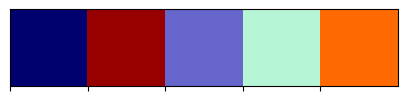

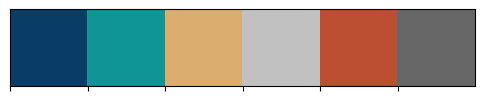

In [3]:
def plot_adjust_settings(xlabel, ylabel, ax=None):
    if ax is None:
        ax = plt.gca()
        
    ax.set_xlabel(xlabel,fontsize=11,labelpad=7)
    ax.set_ylabel(ylabel,fontsize=11,labelpad=7)
    ax.tick_params(labelsize=9, pad=5)
    
seismic_pal = ['#00006e', '#980000', '#6666CC', '#b6f6d6', '#FF6A00']
sns.palplot(seismic_pal)

hex_colors = ['#093c66', '#0f9596', '#dbad6e', '#c1c1c1','#bc4e32', '#676767']
discrete_pal = sns.color_palette(hex_colors)
sns.palplot(discrete_pal)

# Download 

In [8]:
import os
import requests

df = pd.read_csv("GPCRdb_structures.csv")
output_dir = 'RAW'
os.makedirs(output_dir, exist_ok=True)

for pdb_id in df['PDB']:
    pdb_id = pdb_id.lower()
    url = f"https://files.rcsb.org/download/{pdb_id}.pdb"
    out_path = os.path.join(output_dir, f"{pdb_id}.pdb")
    
    if not os.path.exists(out_path):
        try:
            r = requests.get(url)
            r.raise_for_status()
            with open(out_path, 'w') as f:
                f.write(r.text)
        except Exception as e:
            print(f"Failed to download {pdb_id}: {e}")


    PDB UniProt     IUPHAR Receptor family Cl. Species   Method  \
0  3SN6   ADRB2         β2   Adrenoceptors   A   Human    X-ray   
1  6CMO    OPSD  Rhodopsin          Opsins   A   Human  Cryo-EM   
2  6D9H    AA1R         A1       Adenosine   A   Human  Cryo-EM   
3  6DDE    OPRM          μ          Opioid   A   Mouse  Cryo-EM   
4  6DDF    OPRM          μ          Opioid   A   Mouse  Cryo-EM   

                           Refined structure  Resolution Preferred chain  \
0                                          -         3.2               R   
1  https://gpcrdb.org/structure/refined/6CMO         4.5               R   
2  https://gpcrdb.org/structure/refined/6D9H         3.6               R   
3                                          -         3.5               R   
4                                          -         3.5               R   

    State  Degree active (%)  % of Seq Family Subtype Note  % of Seq.1  \
0  Active                100        69     Gs      αs    -        

# Process
- Align all structures to receptor chain of 7f9y
- Extract chain IDs by center of mass coodinates

In [ ]:
# align files
# in directory 
pymol

# align all to 7f9y

# in Pymol console
run ./saveAll.py

In [9]:
# get all aligned files 
files = [f for f in os.listdir("RAW/") if f.endswith("_align.pdb")]
files.sort()
# template
temp = mda.Universe("RAW/7f9y_align.pdb")
rec = temp.select_atoms("segid R").center_of_mass()
alpha = temp.select_atoms("segid A").center_of_mass()

os.makedirs('COMPLEX', exist_ok=True)

for f in files:
    pdbId = f.split("_")[0]
    
    u = mda.Universe("RAW/%s" %f)    
    id_rec = u.select_atoms("point %d %d %d 4.5" %(rec[0], rec[1], rec[2])).residues.segids
    id_alpha = u.select_atoms("point %d %d %d 4.5" %(alpha[0], alpha[1], alpha[2])).residues.segids

    if (len(id_rec)) == 0 or (len(id_alpha)) == 0:
        print(pdbId)
    else:
        sel_rec = u.select_atoms(f'segid {id_rec[0]}')
        sel_alpha = u.select_atoms(f'segid {id_alpha[0]}')
        
        u.add_TopologyAttr('chainID')

        # Assign chain IDs to selections
        sel_rec.segments.segids = ["R"]
        sel_alpha.segments.segids = ["A"]
        
        sel_rec.chainIDs = ['R'] * len(sel_rec)
        sel_alpha.chainIDs = ['A'] * len(sel_alpha)

        merged = mda.Merge(sel_rec, sel_alpha)
        merged.atoms.write(f"COMPLEX/{pdbId}.pdb")

/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:885: UserWarning: Unit cell dimensions not found. CRYST1 record set to unitary values.
  warnings.warn(


8ef5
8ef6
8efl
8efo
8f7q
8f7s


In [10]:
def ExportPDB(universe, selection, outpath):
    sel = universe.select_atoms(selection)
    sel.write(outpath)

def ExportFasta(universe, pdbId, selection, outpath):
    sel = universe.select_atoms(selection)
    seq = "".join([mda.lib.util.convert_aa_code(r.resname) for r in sel.residues])
    with open(outpath, 'w') as f:
        f.write(f">{pdbId}\n{seq}\n")

In [11]:
lst = ["REC", "ALPHA"]
for domain in lst:
    os.makedirs(os.path.join(domain, "CA_PDB"), exist_ok=True)
    os.makedirs(os.path.join(domain, "FASTA"), exist_ok=True)

files = sorted([f for f in os.listdir("COMPLEX/") if f.endswith(".pdb")])

for f in files:
    pdbId = f.split(".")[0]
    u = mda.Universe(f'COMPLEX/{f}')

    sel_rec   = u.select_atoms('protein and chainID R and name CA')
    sel_alpha = u.select_atoms('protein and chainID A and name CA')

    if len(sel_rec) == 0 or len(sel_alpha) == 0:
        continue

    ExportPDB(u, 'protein and chainID R and name CA', f'REC/CA_PDB/{pdbId}.pdb')
    ExportPDB(u, 'protein and chainID A and name CA', f'ALPHA/CA_PDB/{pdbId}.pdb')

    ExportFasta(u, pdbId, 'protein and chainID R and name CA', f'REC/FASTA/{pdbId}.fasta')
    ExportFasta(u, pdbId, 'protein and chainID A and name CA', f'ALPHA/FASTA/{pdbId}.fasta')

# Receptor alignment 
annotated with PDB identifiers

In [22]:
df = pd.read_excel("residue_table.xlsx")
print(df.shape)
print(df.columns.tolist()[:10])
print(df.head(3).to_string())

(388, 201)
['GPCRdb(A)', '5-HT1A receptor Human', '5-HT1B receptor Human', '5-HT1D receptor Human', '5-HT1E receptor Human', '5-HT1F receptor Human', '5-HT2A receptor Human', '5-HT2B receptor Human', '5-HT2C receptor Human', '5-HT4 receptor Human']
      GPCRdb(A) 5-HT1A receptor Human 5-HT1B receptor Human 5-HT1D receptor Human 5-HT1E receptor Human 5-HT1F receptor Human 5-HT2A receptor Human 5-HT2B receptor Human 5-HT2C receptor Human 5-HT4 receptor Human 5-HT5A receptor Human 5-HT6 receptor Human 5-HT7 receptor Human A1 receptor Human A2A receptor Human A2B receptor Human A3 receptor Human ACKR1 Human ACKR3 Human M1 receptor Human M2 receptor Human M3 receptor Human M3 receptor Rat M4 receptor Human M5 receptor Human MC2 receptor Human α1A-adrenoceptor Human α1B-adrenoceptor Human α2A-adrenoceptor Human α2B-adrenoceptor Human α2C-adrenoceptor Human β1-adrenoceptor Human β1-adrenoceptor W. turkey β2-adrenoceptor Human β3-adrenoceptor Dog β3-adrenoceptor Human AT1 receptor Human AT2 r

In [36]:
### GPCRdb residue numbering ###
df = pd.read_excel("residue_table.xlsx")

# drop TM header rows (all receptor columns are NaN in those rows)
df = df.dropna(subset=df.columns[1:], how='all')

# transpose: GPCRdb positions become columns, receptors become rows
df = df.set_index('GPCRdb(A)').T
df.index.name = None
df.reset_index(inplace=True)
df.columns.values[0] = "Receptor"

# process 'Receptor' description
df["Receptor"] = df["Receptor"].str.replace("receptor", "").str.strip()
df['Receptor'] = df['Receptor'].replace({'chemerin  2 Human' : 'chemerin-2 Human'})

# split 'Receptor' column at first space into two new columns
df[['IUPHAR', 'Species']] = df['Receptor'].str.split(' ', n=1, expand=True)

# reorder columns: move new columns to the front and drop original 'Receptor'
cols = ['IUPHAR', 'Species'] + [col for col in df.columns if col not in ['IUPHAR', 'Species', 'Receptor']]
df = df[cols]

# process 'Species' description
df['Species'] = df['Species'].str.strip()

dicoSpecies = {"W. turkey" : "Wild turkey",
              "s. AD169" : "strain AD169",
              "s. AD169.1" : "strain AD169",
              "H. adansoni" : "Hasarius adansoni",
              "J. flying s.." : "Japanese flying squid"}

df['Species'] = df['Species'].replace(dicoSpecies)

# process 'IUPHAR' description
dicoIUPHAR = {"α1A-adrenoceptor" : "α1A",
              "α1B-adrenoceptor" : "α1B",
              "α2A-adrenoceptor" : "α2A",
              "α2B-adrenoceptor" : "α2B",
              "α2C-adrenoceptor" : "α2C",
              "β1-adrenoceptor" : "β1",
              "β2-adrenoceptor" : "β2",
              "β3-adrenoceptor" : "β3"}

df['IUPHAR'] = df['IUPHAR'].replace(dicoIUPHAR)

### PDB info ###
df_pdb = pd.read_csv("GPCRdb_structures.csv")
df_pdb['IUPHAR'] = df_pdb['IUPHAR'].replace({'chemerin 2': 'chemerin-2'})
df_pdb = df_pdb[['IUPHAR', 'Species', 'PDB']]

merged_df = pd.merge(df_pdb, df, how='left', on=['IUPHAR', 'Species'])
merged_df.to_pickle('GPCRdb_structures_alignment.pkl')
merged_df.head()

,IUPHAR,Species,PDB,1x20 1.20x20,1x21 1.21x21,1x22 1.22x22,1x23 1.23x23,1x24 1.24x24,1x25 1.25x25,1x26 1.26x26,...,8x60 8.60x60,8x61 8.61x61,8x62 8.62x62,8x63 8.63x63,8x64 8.64x64,8x65 8.65x65,8x66 8.66x66,8x67 8.67x67,8x68 8.68x68,8x69 8.69x69
0,β2,Human,3SN6,-,-,-,-,-,Q26,E27,...,-,-,-,-,-,-,-,-,-,-
1,Rhodopsin,Human,6CMO,-,-,-,-,-,-,-,...,-,-,-,-,-,-,-,-,-,-
2,A1,Human,6D9H,-,-,-,-,-,-,-,...,D305,H306,F307,R308,C309,Q310,P311,A312,P313,P314
3,μ,Mouse,6DDE,-,-,-,-,-,-,-,...,-,-,-,-,-,-,-,-,-,-
4,μ,Mouse,6DDF,-,-,-,-,-,-,-,...,-,-,-,-,-,-,-,-,-,-


# Export PDB and FASTA

In [40]:
def CreateProcessedPDB(pdbId, residue_dico):
    u = mda.Universe(f"REC/CA_PDB/{pdbId}.pdb")
    sel = u.select_atoms("protein and name CA")

    dicoPdbId = {key: '-' for key in residue_dico}
    strResToKeep = ""

    for res in sel.residues:
        resnum = str(res.resid)
        residue = seq1(res.resname) + resnum  # e.g. "T32"

        for key, value in residue_dico.items():
            if str(value) != '-' and str(value)[1:] == resnum:
                dicoPdbId[key] = residue
                strResToKeep += f"{resnum} "
                break

    os.makedirs("REC/refined_PDB", exist_ok=True)
    if strResToKeep.strip():
        refined = u.select_atoms(f"protein and name CA and resid {strResToKeep.strip()}")
        refined.write(f"REC/refined_PDB/{pdbId}.pdb")

    return dicoPdbId


def ExportFasta(pdbId, dicoPdbId):
    with open("REC/alignement_from_gpcrdb-processed.fasta", 'a') as fo:
        fo.write(f">{pdbId}\n")
        for key, value in dicoPdbId.items():
            fo.write(str(value)[0])  # one-letter AA code or '-'
        fo.write("\n")

In [41]:
df = pd.read_pickle('GPCRdb_structures_alignment.pkl')
df['PDB'] = df['PDB'].str.lower()

pdbs = [f.split('.')[0] for f in os.listdir('REC/CA_PDB') if f.endswith('.pdb')]
pdbs.sort() 

for pdbId in pdbs:
    row = df[df['PDB'] == pdbId]
    row_dict = row.iloc[0, 3:].to_dict()
    
    # export PDB comprising residue numbers that are represented in aligned GPCRdb sequence
    print(pdbId)
    dicoPdbId = CreateProcessedPDB(pdbId, row_dict)
    
    # export fasta
    ExportFasta(pdbId, dicoPdbId) 

3sn6
6cmo


/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:885: UserWarning: Unit cell dimensions not found. CRYST1 record set to unitary values.
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'formalcharges' Using default value of '0'
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:885: UserWarning: Unit cell dimensions not found. CRY

6d9h
6dde
6ddf
6gdg


/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:885: UserWarning: Unit cell dimensions not found. CRYST1 record set to unitary values.
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'formalcharges' Using default value of '0'
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:885: UserWarning: Unit cell dimensions not found. CRY

6kpf
6kpg


/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:885: UserWarning: Unit cell dimensions not found. CRYST1 record set to unitary values.
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'formalcharges' Using default value of '0'
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:885: UserWarning: Unit cell dimensions not found. CRYST1 record set to unitary values.
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'formalcharges' Using defaul

... (242 outputs left out)

8zps
8zpt
8zqe
8zsj
8zsp
9ast


/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:885: UserWarning: Unit cell dimensions not found. CRYST1 record set to unitary values.
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'formalcharges' Using default value of '0'
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:885: UserWarning: Unit cell dimensions not found. CRY

9bkj
9iy8
9jkq
9k1c


/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:885: UserWarning: Unit cell dimensions not found. CRYST1 record set to unitary values.
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'formalcharges' Using default value of '0'
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:885: UserWarning: Unit cell dimensions not found. CRY

# Generate structure ensembles of equal sequence length

In [44]:
class receptor():
    def __init__(self, name, pdbId=""):
        self.name = name
        self.pdbId = pdbId
        self.seq = ""
        self.globseq = ""
        self.listResid = []
        self.globseq2speseq = {}
        self.PDB = None
        self.LoadPDB(name)

    def LoadPDB(self, fi):
        self.PDB = mda.Universe(fi)
        sel = self.PDB.select_atoms("protein and name CA")
        self.seq = "".join([seq1(r.resname) for r in sel.residues])
        self.listResid = list(sel.residues.resids)

    def AddToGlobseq(self, text):
        self.globseq += text

    def fromGlob2Spe(self):
        cnt = 0
        for i in range(len(self.globseq)):
            if self.globseq[i] != "-":
                if self.globseq[i] == self.seq[cnt]:
                    self.globseq2speseq[i] = self.listResid[cnt]
                cnt += 1
        return self.globseq2speseq

    def ExportPDB(self, outpath, selection):
        sel = self.PDB.select_atoms(selection)
        sel.write(outpath)


def parseFasta(parent_dir, fileName):
    dicoRec = {}
    fAlign = open(parent_dir + "/" + fileName, 'r')
    for line in fAlign:
        if ">" in line:
            pdbId = line[1:-1]
            pdbFile = parent_dir + "/refined_PDB/" + pdbId + ".pdb"
        else:
            seq = line[:-1]
            try:
                dicoRec[pdbId].AddToGlobseq(seq)
            except KeyError:
                dicoRec[pdbId] = receptor(pdbFile, pdbId)
                dicoRec[pdbId].AddToGlobseq(seq)
    return dicoRec


def defineRefGlob(dicoRec, t=0):
    """
    Identify reliable alignment positions across receptor sequences.

    Parameters:
        dicoRec (dict): Dictionary of receptor objects, each with a globseq attribute.
        t (int): Maximum number of allowed gaps at a position to still consider it reliable.

    Returns:
        listId (list): List of indices corresponding to positions considered reliable.
        listUnknown (list): List of PDB IDs that had gaps at tolerated positions.
    """
    seqs = [rec.globseq for rec in dicoRec.values()]
    size = len(seqs[0])
    listId = []
    listUnknown = set()

    for i in range(size):
        gaps = [key for key, rec in dicoRec.items() if rec.globseq[i] == "-"]
        if len(gaps) <= t:
            listId.append(i)
            listUnknown.update(gaps)

    return listId, list(listUnknown)

def compactSel(resSel):
    sel = resSel.split()
    newResSel = "%d " %int(sel[0])
    prevRes = int(sel[0])
    add = False
    for i in range(1, len(sel), 1):
        if (prevRes + 1) == int(sel[i]):
            add = True
        else:
            if add:
                newResSel += "to %d %s " %(prevRes, sel[i])
            else:
                newResSel += "%s " %sel[i]
            add = False
        prevRes = int(sel[i])
    if add:
        newResSel += "to %d " %(prevRes)
    return newResSel

## Receptor

In [55]:
parent_dir = "REC"
dicoRec = parseFasta(parent_dir, "alignement_from_gpcrdb-processed.fasta")

for i in range(0, 40, 1):
    directory = os.path.join(parent_dir, "U%d" %i)    
    if not os.path.exists(directory):
        os.makedirs(directory)
        
    listId, listUnknown = defineRefGlob(dicoRec, i)

    foSkip = open(parent_dir + "/ulist%d.dat" %i, 'w')
    foSkip.write("seqLength= %d ; structures deleted= %d\n" %(len(listId), len(listUnknown)))

    for u in listUnknown:
        foSkip.write("%s " %u)
    foSkip.write("\n")
    foSkip.close()

    # No reliable positions in sequence
    if len(listId) == 0:
        pass
    else:
        for key, val in dicoRec.items():
            write = True
            if key not in listUnknown:
                dicoRec[key].fromGlob2Spe()
                resSel = ""
                for index in listId:
                    try:
                        resSel += str(dicoRec[key].globseq2speseq[index]) + " "
                    except KeyError:
                        print("########### Error in pdb:", dicoRec[key].pdbId)
                        write = False
                if write:
                    dicoRec[key].ExportPDB(f'{parent_dir}/U{i}/{dicoRec[key].pdbId}_common_ca.pdb', "protein and name CA and resid " + compactSel(resSel))

## G protein

In [ ]:
%%bash
# create fasta file to perform sequence alignment with muscle
cat ALPHA/FASTA/*.fasta > ALPHA/muscle-alpha.txt
muscle -align ALPHA/muscle-alpha.txt -output ALPHA/muscle-alpha-aligned.fasta

In [49]:
os.makedirs("ALPHA/refined_PDB", exist_ok=True)
for f in glob.glob("ALPHA/CA_PDB/*.pdb"):
    shutil.copy(f, f.replace("CA_PDB", "refined_PDB"))

parent_dir = "ALPHA"
dicoRec = parseFasta(parent_dir, "muscle-alpha-aligned.fasta")

i = 10
    
directory = os.path.join(parent_dir, "U%d" %i)    
if not os.path.exists(directory):
    os.makedirs(directory)
    
listId, listUnknown = defineRefGlob(dicoRec, i)

foSkip = open(parent_dir + "/ulist%d.dat" %i, 'w')
foSkip.write("seqLength= %d ; structures deleted= %d\n" %(len(listId), len(listUnknown)))

for u in listUnknown:
    foSkip.write("%s " %u)
foSkip.write("\n")
foSkip.close()

# No reliable positions in sequence
if len(listId) == 0:
    pass
else:
    for key, val in dicoRec.items():
        write = True
        if key not in listUnknown:
            dicoRec[key].fromGlob2Spe()
            resSel = ""
            for index in listId:
                try:
                    resSel += str(dicoRec[key].globseq2speseq[index]) + " "
                except KeyError:
                    print("########### Error in pdb:", dicoRec[key].pdbId)
                    write = False
            if write:
                dicoRec[key].ExportPDB(f'{parent_dir}/U{i}/{dicoRec[key].pdbId}_common_ca.pdb', "protein and name CA and resid " + compactSel(resSel))


## Merge Receptor and G-Protein

In [57]:
topdir = "PROCESSED"
if os.path.exists("PROCESSED"):
    shutil.rmtree("PROCESSED")
os.makedirs("PROCESSED")

recList = [f.split("_")[0] for f in os.listdir("REC/U35") if f.endswith("_common_ca.pdb")]
alphaList = [f.split("_")[0] for f in os.listdir("ALPHA/U10") if f.endswith("_common_ca.pdb")]

for rec in recList:
    if rec in alphaList:
        # concatenate and remove END lines
        lines = []
        for src in [f"REC/U35/{rec}_common_ca.pdb", f"ALPHA/U10/{rec}_common_ca.pdb"]:
            with open(src) as f:
                lines += [l for l in f.readlines() if not l.strip() == "END"]
        with open(f"PROCESSED/{rec}.pdb", "w") as f:
            f.writelines(lines)

In [60]:
topdir = "PROCESSED"

files = sorted(glob.glob(f'{topdir}/????.pdb'))
ref = mda.Universe(f'{topdir}/7f9y.pdb')
n_ref = len(ref.atoms)

# keep only files with matching atom count
files_ok = []
for f in files:
    u_tmp = mda.Universe(f)
    if len(u_tmp.atoms) == n_ref:
        files_ok.append(f)
    else:
        print(f"Skipping {f}: {len(u_tmp.atoms)} atoms (expected {n_ref})")

print(f"{len(files_ok)}/{len(files)} files kept")

u = mda.Universe(files_ok[0], files_ok)

align.AlignTraj(u, ref,
                select='chainID R',
                filename=f'{topdir}/traj.xtc').run()

Skipping PROCESSED/7t2g.pdb: 423 atoms (expected 422)
Skipping PROCESSED/7t90.pdb: 423 atoms (expected 422)
Skipping PROCESSED/7vla.pdb: 423 atoms (expected 422)
Skipping PROCESSED/8gfv.pdb: 423 atoms (expected 422)
Skipping PROCESSED/8unm.pdb: 423 atoms (expected 422)
Skipping PROCESSED/8unn.pdb: 423 atoms (expected 422)
Skipping PROCESSED/8unq.pdb: 423 atoms (expected 422)
Skipping PROCESSED/8unr.pdb: 423 atoms (expected 422)
Skipping PROCESSED/8uns.pdb: 423 atoms (expected 422)
Skipping PROCESSED/8unt.pdb: 423 atoms (expected 422)
Skipping PROCESSED/8unu.pdb: 423 atoms (expected 422)
Skipping PROCESSED/8unv.pdb: 423 atoms (expected 422)
Skipping PROCESSED/8unw.pdb: 423 atoms (expected 422)
Skipping PROCESSED/8unx.pdb: 423 atoms (expected 422)
Skipping PROCESSED/8uny.pdb: 423 atoms (expected 422)
Skipping PROCESSED/8uo0.pdb: 423 atoms (expected 422)
192/208 files kept


/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/base.py:730: UserWarning: Reader has no dt information, set to 1.0 ps
  return self.ts.dt
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/analysis/base.py:562: UserWarning: Reader has no dt information, set to 1.0 ps
  self.times[idx] = ts.time
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/XTC.py:119: UserWarning: Reader has no dt information, set to 1.0 ps
  time = ts.time


# Tilt and Shift

In [61]:
topdir = 'PROCESSED'

# Input
ref = mda.Universe(f'{topdir}/7f9y.pdb')
rec = ref.select_atoms('chainID R')
print(rec.resids)
u = mda.Universe(f'{topdir}/7f9y.pdb', f'{topdir}/traj.xtc')

# Step 1: orient reference
rec_coords = rec.positions - rec.center_of_mass()

# Get principal axes
rec_axes = rec.principal_axes()


# Step 2: rotate rec principal axis to align with z-axis
R1 = R.align_vectors([[0, 0, -1]], [rec_axes[2]])[0]

ref.atoms.positions = R1.apply(ref.atoms.positions - rec.center_of_mass())

# Step 4: align traj receptor to rotated ref receptor
sel_ref = ref.select_atoms('all')
sel_ref.write(f'{topdir}/7f9y-align.pdb')

aligner = align.AlignTraj(u, ref, select='chainID R', filename=f'{topdir}/traj-align.xtc').run()

[ 45  46  47  48  49  50  51  52  53  54  55  56  57  58  59  60  61  62
  63  64  65  66  67  68  69  70  71  76  77  78  79  80  81  82  83  84
  85  86  87  88  89  90  91  92  93  94  95  96  97  98  99 100 101 102
 103 104 105 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123
 124 125 126 127 128 129 130 131 132 133 134 135 136 137 138 139 140 141
 142 143 144 145 146 147 148 149 150 151 152 153 154 156 157 158 159 160
 161 162 163 164 165 166 167 168 169 170 171 172 173 174 175 176 177 178
 179 180 198 199 200 210 211 212 213 214 215 216 217 218 219 220 221 222
 223 224 225 226 227 228 229 230 231 232 233 234 235 236 237 238 239 240
 241 259 260 261 262 263 264 265 266 267 268 269 270 271 272 273 274 275
 276 277 278 279 280 281 282 283 284 285 286 287 288 289 301 302 303 304
 305 306 307 308 309 310 311 312 313 314 315 316 317 318 319 320 321 322
 323 324 325 327 328 329 330 331 332 333 334]


/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:885: UserWarning: Unit cell dimensions not found. CRYST1 record set to unitary values.
  warnings.warn(
/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:1282: UserWarning: Found no information for attr: 'formalcharges' Using default value of '0'
  warnings.warn(


In [80]:
topdir = 'PROCESSED'

u = mda.Universe(f'{topdir}/7f9y-align.pdb', f'{topdir}/traj-align.xtc')
helix = u.select_atoms('chainID A and resid 369-392')
c_ter = u.select_atoms('chainID A and resid 390-392')
res1 = u.select_atoms('name CA and resid 68 and chainID R')
res2 = u.select_atoms('name CA and resid 259 and chainID R')

ref = mda.Universe(f'{topdir}/7f9y-align.pdb')
helix_ref = ref.select_atoms('chainID A and resid 369-392')
c_ter_ref = ref.select_atoms('chainID A and resid 390-392')

z_axis = np.array([0, 0, 1])

dico = {'Tilt': [], 'Shift': [], 'Distance': []}

for ts in u.trajectory:
    helix_axis = helix.principal_axes()[2]

    tilt_rad = np.arccos(np.abs(np.dot(helix_axis, z_axis)) / np.linalg.norm(helix_axis))
    dico['Tilt'].append(90 - np.degrees(tilt_rad))

    y_shift = c_ter.center_of_mass()[1] - c_ter_ref.center_of_mass()[1]
    dico['Shift'].append(y_shift)

    dist = np.linalg.norm(res1.positions[0] - res2.positions[0])
    dico['Distance'].append(dist)

df = pd.DataFrame(dico)

pdbs = [os.path.basename(f).split('.')[0].upper() for f in files_ok]
pdbs.sort()
df['PDB'] = np.array(pdbs)

anno = pd.read_csv("GPCRdb_structures.csv")
merged = pd.merge(df, anno, how='left', on=['PDB'])
merged = merged[merged['PDB'] != '6OSA']
merged.to_pickle(f'../exp-gprot-distance-tilt-shift.pkl')

/Users/roessner/miniconda3/envs/phd/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(


          Tilt     Shift   Distance   PDB UniProt     IUPHAR  \
0    56.003012 -6.736334  31.678793  3SN6   ADRB2         β2   
1    58.650750 -0.293000  29.973768  6CMO    OPSD  Rhodopsin   
2    49.357985 -5.209667  30.065897  6GDG   AA2AR        A2A   
3    54.729085 -5.949667  31.734079  6NI3   ADRB2         β2   
4    58.867096 -4.436334  29.352028  6OIJ    ACM1         M1   
..         ...       ...        ...   ...     ...        ...   
187  65.347549 -0.223000  25.900185  8ZQE   GPR15      GPR15   
188  50.012312 -5.829667  29.152428  8ZSJ   TAAR1        TA1   
189  49.964591 -5.666334  29.567308  8ZSP   TAAR1        TA1   
190  65.527787 -1.126333  27.100584  9AST    XCR1       XCR1   
191  49.917004 -5.853000  29.076265  9JKQ   TAAR1        TA1   

                Receptor family Cl. Species   Method  ...   State  \
0                 Adrenoceptors   A   Human    X-ray  ...  Active   
1                        Opsins   A   Human  Cryo-EM  ...  Active   
2                     Ad

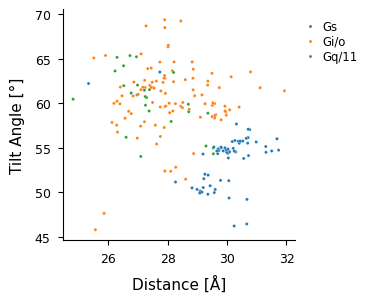

In [81]:
topdir = 'PROCESSED'

fig, ax = plt.subplots(1,1,figsize=(3,3))

df = pd.read_pickle(f'../exp-gprot-distance-tilt-shift.pkl')
print(df[df['Tilt'] < 75])


sns.scatterplot(data=df, x='Distance', y='Tilt', hue='Family', ax=ax, s=5)

ax.legend(title='', loc='upper left', fontsize='small', handlelength=0.7, labelspacing=0.2, frameon=False, bbox_to_anchor=(1,1))

plot_adjust_settings('Distance [Å]', 'Tilt Angle [°]', ax=ax)
sns.despine()